# CS542 - CIFAR-100 OOD Challenge
**Aayush Kumar**

This notebook contains all three required parts.

## How to use

Set `MODE` in the **Configuration** cell below:

| MODE | What it does | Approx. time |
|------|---|---|
| `"demo"` | Defines all architectures and runs 1-batch sanity checks. **No training, no real submission.**
| `"inference"` | Downloads pretrained checkpoints (if URL is configured), generates the OOD submission CSV. (This wont work on colab)
| `"full"` | Trains all three parts from scratch end-to-end.

> **Colab free tier disconnects after ~12 hours.** `MODE="full"` will not finish in one session on free Colab. Use Colab Pro, or run on a local GPU / cluster, or use `MODE="inference"` with pre-trained checkpoints.


In [ ]:
# Configuration — set MODE then Run All

import os, sys, time

# MODE: "demo" | "inference" | "full"
MODE = "full"

# ---- Optional: URL to a public .zip / .tar.gz of pretrained checkpoints
# If you have your trained .best.pt files hosted on Google Drive, HuggingFace,
# or any direct-download URL, paste it below. Leave as None to skip.
# Expected archive contents (flat):
#     part1_ckpt.pt.best.pt
#     part2_ckpt.pt.best.pt
#     part3_ckpt.pt.best.pt
CHECKPOINTS_URL = None  # e.g. "https://huggingface.co/.../resolve/main/ckpts.tar.gz"

# Reproducibility
SEED = 42

# Auto-detect environment
IN_COLAB = "google.colab" in sys.modules
IS_SCC = os.path.exists("/projectnb")
HAS_CUDA = False  # filled in after torch import below
HAS_MPS = False

# Working directory (auto)
# Colab: /content/cs541_work  (ephemeral, fine)
# SCC:   $WORK_ROOT env var if set, else $HOME/cs541_work
# Local: ./cs541_work
if IN_COLAB:
    WORK_ROOT = "/content/cs541_work"
elif IS_SCC:
    WORK_ROOT = os.environ.get("WORK_ROOT", os.path.expanduser("~/cs541_work"))
else:
    WORK_ROOT = os.path.abspath("./cs541_work")

os.makedirs(WORK_ROOT, exist_ok=True)
DATA_ROOT = os.path.join(WORK_ROOT, "data")
OOD_DIR = os.path.join(WORK_ROOT, "ood-test-CS541")
SUBMISSION_PATH = os.path.join(WORK_ROOT, "submission_ood.csv")

# Checkpoint paths
CKPT_PART1 = os.path.join(WORK_ROOT, "part1_ckpt.pt")
CKPT_PART2 = os.path.join(WORK_ROOT, "part2_ckpt.pt")
CKPT_PART3 = os.path.join(WORK_ROOT, "part3_ckpt.pt")


# Per-part training config
# Demo mode runs tiny smoke tests; full mode runs real training.
DEMO_MODE = (MODE == "demo")

CFG_PART1 = {
    "batch_size": 128,
    "epochs": 1 if DEMO_MODE else 100,
    "lr": 0.1,
    "weight_decay": 5e-4,
    "momentum": 0.9,
    "label_smoothing": 0.1,
    "mixup_alpha": 0.2,
}
CFG_PART2 = {
    "batch_size": 64,
    "epochs": 1 if DEMO_MODE else 30,
    "lr": 1e-4,
    "weight_decay": 0.05,
    "label_smoothing": 0.1,
}
CFG_PART3 = {
    "target_size": 448,
    "batch_size": 8,               # drop to 4 if OOM (448x448 + 305M params)
    "head_epochs": 1 if DEMO_MODE else 3,
    "ft_epochs": 2 if DEMO_MODE else 12,
    "head_lr": 1e-3,
    "ft_lr": 1e-5,
    "ft_lr_head": 5e-5,            # head LR during full fine-tune = ft_lr * 5
    "warmup_epochs": 0 if DEMO_MODE else 2,
    "weight_decay": 0.05,
    "label_smoothing": 0.1,
    "mixup_alpha": 0.2,
    "cutmix_alpha": 1.0,
    "mixup_prob": 0.5,
    "corruption_p": 0.5,
    "corruption_max_severity": 3,
}

print("=" * 70)
print(f"MODE          : {MODE}")
print(f"IN_COLAB      : {IN_COLAB}")
print(f"IS_SCC        : {IS_SCC}")
print(f"WORK_ROOT     : {WORK_ROOT}")
print(f"CHECKPOINTS_URL : {CHECKPOINTS_URL}")
print("=" * 70)

assert MODE in ("demo", "inference", "full"), \
    f"MODE must be 'demo', 'inference', or 'full'; got {MODE!r}"


MODE          : full
IN_COLAB      : False
IS_SCC        : True
WORK_ROOT     : /usr4/cs598/aayushks/cs541_work
CHECKPOINTS_URL : None


In [ ]:
# Install dependencies (Colab needs timm + huggingface_hub explicitly)

import importlib, subprocess, sys

required = {
    "torch": "torch",
    "torchvision": "torchvision",
    "tqdm": "tqdm",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "huggingface_hub": "huggingface_hub",
    "timm": "timm",
    "PIL": "pillow",
}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    print(f"Installing: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

print("Environment ready.")


Environment ready.


In [ ]:
import io, json, math, random, urllib.request
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm
from PIL import Image, ImageFilter, ImageOps

# Update environment flags now that torch is loaded
HAS_CUDA = torch.cuda.is_available()
HAS_MPS = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()


def get_device() -> torch.device:
    """CUDA > MPS > CPU."""
    if HAS_CUDA:
        return torch.device("cuda")
    if HAS_MPS:
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if HAS_CUDA:
        torch.cuda.manual_seed_all(seed)


def num_workers_default() -> int:
    """Pick a reasonable num_workers for the current environment."""
    if IN_COLAB:
        return 2
    try:
        return min(int(os.environ.get("NSLOTS", os.cpu_count() or 4)), 8)
    except Exception:
        return 4


set_seed(SEED)
device = get_device()
print(f"Device: {device}")
if HAS_CUDA:
    print(f"GPU   : {torch.cuda.get_device_name(0)}")


/projectnb/cs505am/students/aayushks/other/cifar100_challenge/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
GPU   : NVIDIA H200 NVL


In [ ]:
# Download pretrained checkpoints (only used in MODE="inference")

def maybe_download_checkpoints():
    """If CHECKPOINTS_URL is set and we don't already have the checkpoints,
    download and extract them into WORK_ROOT. Supports .zip and .tar.gz."""
    if not CHECKPOINTS_URL:
        return False

    targets = [CKPT_PART1 + ".best.pt", CKPT_PART2 + ".best.pt", CKPT_PART3 + ".best.pt"]
    if all(os.path.exists(t) for t in targets):
        print("Checkpoints already present. Skipping download.")
        return True

    print(f"Downloading checkpoints from {CHECKPOINTS_URL} ...")
    archive_path = os.path.join(WORK_ROOT, "_ckpts_download")
    urllib.request.urlretrieve(CHECKPOINTS_URL, archive_path)

    # Detect format and extract
    if CHECKPOINTS_URL.endswith(".zip"):
        import zipfile
        with zipfile.ZipFile(archive_path) as z:
            z.extractall(WORK_ROOT)
    elif CHECKPOINTS_URL.endswith((".tar.gz", ".tgz", ".tar")):
        import tarfile
        with tarfile.open(archive_path) as t:
            t.extractall(WORK_ROOT)
    else:
        # Assume it's a single file — rename based on convention not supported
        print("WARNING: CHECKPOINTS_URL is not a .zip / .tar.gz; expected an archive containing all 3 .best.pt files.")
        return False

    os.remove(archive_path)
    found = [t for t in targets if os.path.exists(t)]
    print(f"Extracted {len(found)}/3 expected checkpoints.")
    return len(found) > 0


if MODE == "inference":
    ok = maybe_download_checkpoints()
    if not ok:
        print()
        print("=" * 70)
        print("WARNING: MODE='inference' but no checkpoints could be loaded.")
        print("Falling back to MODE='demo' (architectures only, no real submission).")
        print("To use inference mode, set CHECKPOINTS_URL in the config cell.")
        print("=" * 70)
        MODE = "demo"
        DEMO_MODE = True
        for cfg in (CFG_PART1, CFG_PART2, CFG_PART3):
            cfg["epochs"] = 1
            if "warmup_epochs" in cfg:
                cfg["warmup_epochs"] = 0


In [ ]:
# CIFAR-100 data loaders

def make_loaders(batch_size: int, num_workers: int,
                 train_transform=None, val_transform=None,
                 fast=False) -> Tuple[DataLoader, DataLoader, DataLoader]:
    mean = (0.5071, 0.4867, 0.4408)  ### DO NOT CHANGE THIS
    std = (0.2675, 0.2565, 0.2761)   ### DO NOT CHANGE THIS

    if train_transform is None:
        train_transform = transforms.Compose([
            transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ])
    if val_transform is None:
        val_transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ])

    train_full = datasets.CIFAR100(root=DATA_ROOT, train=True, download=True, transform=train_transform)
    val_full = datasets.CIFAR100(root=DATA_ROOT, train=True, download=True, transform=val_transform)
    test_ds = datasets.CIFAR100(root=DATA_ROOT, train=False, download=True, transform=val_transform)

    n = len(train_full)
    n_train = int(0.9 * n)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(n, generator=g).tolist()
    train_ds = Subset(train_full, perm[:n_train])
    val_ds = Subset(val_full, perm[n_train:])

    if fast:
        train_ds = Subset(train_ds, range(min(256, len(train_ds))))
        val_ds = Subset(val_ds, range(min(256, len(val_ds))))
        test_ds = Subset(test_ds, range(min(256, len(test_ds))))

    pin = HAS_CUDA
    persistent = num_workers > 0
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=pin,
                              persistent_workers=persistent, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                            num_workers=num_workers, pin_memory=pin,
                            persistent_workers=persistent)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=pin,
                             persistent_workers=persistent)
    return train_loader, val_loader, test_loader


@torch.no_grad()
def eval_clean(model: nn.Module, loader: DataLoader, device: torch.device) -> float:
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        if isinstance(logits, tuple):
            logits = logits[0]
        correct += (logits.argmax(1) == y).sum().item()
        total += y.numel()
    return 100.0 * correct / total


In [ ]:
# CIFAR-C-style corruption operators (used by Part 3 augmentation)
# Calibrated by visual inspection to match the 20 OOD test distortions.

def _to_pil(img):
    if isinstance(img, Image.Image):
        return img
    return Image.fromarray(np.array(img))


def add_gaussian_noise(img: Image.Image, severity: int) -> Image.Image:
    sigma = [0.04, 0.06, 0.08, 0.09, 0.10][severity - 1] * 255
    arr = np.array(img).astype(np.float32)
    arr += np.random.normal(0, sigma, arr.shape)
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))


def add_shot_noise(img: Image.Image, severity: int) -> Image.Image:
    c = [60, 25, 12, 5, 3][severity - 1]
    arr = np.array(img).astype(np.float32) / 255.0
    arr = np.random.poisson(arr * c) / c
    return Image.fromarray(np.clip(arr * 255, 0, 255).astype(np.uint8))


def add_impulse_noise(img: Image.Image, severity: int) -> Image.Image:
    p = [0.01, 0.02, 0.03, 0.05, 0.07][severity - 1]
    arr = np.array(img).copy()
    mask = np.random.random(arr.shape[:2])
    arr[mask < p / 2] = 0
    arr[mask > 1 - p / 2] = 255
    return Image.fromarray(arr)


def defocus_blur(img: Image.Image, severity: int) -> Image.Image:
    radius = [0.7, 1.0, 1.5, 2.0, 2.5][severity - 1]
    return img.filter(ImageFilter.GaussianBlur(radius=radius))


def motion_blur(img: Image.Image, severity: int) -> Image.Image:
    # Simplified: directional Gaussian
    radius = [1.0, 1.5, 2.0, 2.5, 3.0][severity - 1]
    return img.filter(ImageFilter.GaussianBlur(radius=radius))


def zoom_blur(img: Image.Image, severity: int) -> Image.Image:
    radius = [0.5, 1.0, 1.5, 2.0, 2.5][severity - 1]
    return img.filter(ImageFilter.GaussianBlur(radius=radius))


def fog(img: Image.Image, severity: int) -> Image.Image:
    factor = [0.15, 0.25, 0.35, 0.45, 0.55][severity - 1]
    arr = np.array(img).astype(np.float32) / 255.0
    overlay = np.array([0.85, 0.92, 1.0]) * 255  # bluish-white
    arr = arr * (1 - factor) + (overlay / 255.0) * factor
    return Image.fromarray(np.clip(arr * 255, 0, 255).astype(np.uint8))


def brightness(img: Image.Image, severity: int) -> Image.Image:
    factor = [0.1, 0.2, 0.3, 0.4, 0.5][severity - 1]
    arr = np.array(img).astype(np.float32) / 255.0
    arr = np.clip(arr + factor, 0, 1)
    return Image.fromarray((arr * 255).astype(np.uint8))


def contrast(img: Image.Image, severity: int) -> Image.Image:
    factor = [0.75, 0.5, 0.4, 0.3, 0.2][severity - 1]
    arr = np.array(img).astype(np.float32) / 255.0
    mean_val = arr.mean(axis=(0, 1), keepdims=True)
    arr = (arr - mean_val) * factor + mean_val
    return Image.fromarray(np.clip(arr * 255, 0, 255).astype(np.uint8))


def jpeg_compression(img: Image.Image, severity: int) -> Image.Image:
    q = [80, 65, 50, 35, 25][severity - 1]
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=q)
    buf.seek(0)
    return Image.open(buf).copy()


def pixelate(img: Image.Image, severity: int) -> Image.Image:
    factor = [0.85, 0.75, 0.6, 0.5, 0.4][severity - 1]
    w, h = img.size
    small = img.resize((max(1, int(w * factor)), max(1, int(h * factor))), Image.BOX)
    return small.resize((w, h), Image.NEAREST)


def saturate(img: Image.Image, severity: int) -> Image.Image:
    factor = [1.5, 2.0, 2.5, 3.0, 3.5][severity - 1]
    arr = np.array(img).astype(np.float32) / 255.0
    grey = arr.mean(axis=2, keepdims=True)
    arr = grey + (arr - grey) * factor
    return Image.fromarray(np.clip(arr * 255, 0, 255).astype(np.uint8))


def grayscale(img: Image.Image, severity: int) -> Image.Image:
    return ImageOps.grayscale(img).convert("RGB")


def spatter(img: Image.Image, severity: int) -> Image.Image:
    p = [0.005, 0.01, 0.02, 0.03, 0.04][severity - 1]
    arr = np.array(img).copy()
    mask = np.random.random(arr.shape[:2]) < p
    arr[mask] = 0
    return Image.fromarray(arr)


CIFAR_C_OPS = [
    add_gaussian_noise, add_shot_noise, add_impulse_noise,
    defocus_blur, motion_blur, zoom_blur,
    fog, brightness, contrast,
    jpeg_compression, pixelate, saturate,
    grayscale, spatter,
]


class CifarCAugment:
    """Apply a random CIFAR-C-style corruption with given probability and max severity."""
    def __init__(self, p: float = 0.5, max_severity: int = 3):
        self.p = p
        self.max_severity = max_severity

    def __call__(self, img: Image.Image) -> Image.Image:
        img = _to_pil(img)
        if np.random.rand() > self.p:
            return img
        op = np.random.choice(CIFAR_C_OPS)
        sev = np.random.randint(1, self.max_severity + 1)
        try:
            return op(img, sev)
        except Exception:
            return img


## Part 1 — Wide ResNet-28-10 (from scratch)

A classic CIFAR-native architecture (~36.5M params) trained from scratch on 32×32 inputs with random crops, horizontal flips, MixUp, label smoothing, and SGD with cosine LR decay over 100 epochs.

**Kaggle OOD accuracy: 69.06%**


In [ ]:
# Part 1: WRN-28-10 architecture
class _WRNBasicBlock(nn.Module):
    def __init__(self, in_planes, out_planes, stride, dropRate=0.0):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_planes); self.relu1 = nn.ReLU(inplace=True)
        self.conv1 = nn.Conv2d(in_planes, out_planes, 3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_planes); self.relu2 = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_planes, out_planes, 3, stride=1, padding=1, bias=False)
        self.droprate = dropRate
        self.equalInOut = (in_planes == out_planes)
        self.convShortcut = None if self.equalInOut else nn.Conv2d(in_planes, out_planes, 1, stride=stride, padding=0, bias=False)

    def forward(self, x):
        if not self.equalInOut:
            x = self.relu1(self.bn1(x)); out = x
        else:
            out = self.relu1(self.bn1(x))
        out = self.relu2(self.bn2(self.conv1(out)))
        if self.droprate > 0:
            out = F.dropout(out, p=self.droprate, training=self.training)
        out = self.conv2(out)
        return (x if self.equalInOut else self.convShortcut(x)) + out


class WideResNet(nn.Module):
    def __init__(self, depth: int = 28, widen_factor: int = 10, dropRate: float = 0.3, num_classes: int = 100):
        super().__init__()
        nC = [16, 16 * widen_factor, 32 * widen_factor, 64 * widen_factor]
        n = (depth - 4) // 6
        self.conv1 = nn.Conv2d(3, nC[0], 3, stride=1, padding=1, bias=False)
        self.block1 = self._make_layer(n, nC[0], nC[1], 1, dropRate)
        self.block2 = self._make_layer(n, nC[1], nC[2], 2, dropRate)
        self.block3 = self._make_layer(n, nC[2], nC[3], 2, dropRate)
        self.bn1 = nn.BatchNorm2d(nC[3]); self.relu = nn.ReLU(inplace=True)
        self.fc = nn.Linear(nC[3], num_classes)
        self.nChannels = nC[3]
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1); nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, nb, in_planes, out_planes, stride, dropRate):
        layers = []
        for i in range(int(nb)):
            layers.append(_WRNBasicBlock(in_planes if i == 0 else out_planes, out_planes,
                                         stride if i == 0 else 1, dropRate))
        return nn.Sequential(*layers)

    def forward(self, x):
        out = self.conv1(x)
        out = self.block1(out); out = self.block2(out); out = self.block3(out)
        out = self.relu(self.bn1(out))
        out = F.avg_pool2d(out, 8).view(-1, self.nChannels)
        return self.fc(out)


# Sanity check
_p1 = WideResNet().to(device)
_n_params = sum(p.numel() for p in _p1.parameters()) / 1e6
print(f"WRN-28-10 parameters: {_n_params:.1f}M")
with torch.no_grad():
    _y = _p1(torch.randn(2, 3, 32, 32, device=device))
print(f"Forward shape: {tuple(_y.shape)}")
del _p1


WRN-28-10 parameters: 36.5M
Forward shape: (2, 100)


In [ ]:
# Part 1 training
def mixup_data(x, y, alpha=0.2):
    lam = float(np.random.beta(alpha, alpha)) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam


def fit_part1(model, train_loader, val_loader, optimizer, criterion, scheduler,
              epochs, mixup_alpha, ckpt_path):
    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    best_val = -1.0
    use_amp = (device.type == "cuda")
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    for ep in range(1, epochs + 1):
        model.train()
        tr_c, tr_t, tr_l = 0, 0, 0.0
        for x, y in tqdm(train_loader, desc=f"P1 train {ep}/{epochs}", leave=False):
            x = x.to(device, non_blocking=True); y = y.to(device, non_blocking=True)
            mx, ya, yb, lam = mixup_data(x, y, mixup_alpha)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(mx)
                loss = lam * criterion(logits, ya) + (1 - lam) * criterion(logits, yb)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            with torch.no_grad():
                tr_c += (logits.argmax(1) == y).sum().item(); tr_t += y.numel()
                tr_l += loss.item() * y.numel()
        if scheduler is not None: scheduler.step()

        model.eval()
        va_c, va_t, va_l = 0, 0, 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                va_l += F.cross_entropy(logits, y).item() * y.numel()
                va_c += (logits.argmax(1) == y).sum().item(); va_t += y.numel()
        tr_a = tr_c / max(tr_t, 1); va_a = va_c / max(va_t, 1)
        history["train_acc"].append(tr_a); history["val_acc"].append(va_a)
        history["train_loss"].append(tr_l / max(tr_t, 1))
        history["val_loss"].append(va_l / max(va_t, 1))
        print(f"  Epoch {ep:03d}/{epochs} | train_acc {tr_a:.4f} | val_acc {va_a:.4f}")

        if va_a > best_val:
            best_val = va_a
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()},
                       ckpt_path + ".best.pt")
    return history, best_val


# Build model
part1_history = None  # ensure defined even if construction fails
part1_model = WideResNet(depth=28, widen_factor=10, dropRate=0.3, num_classes=100).to(device)

if MODE == "full":
    print(">>> Part 1: training WRN-28-10 from scratch")
    nw = num_workers_default()
    train_loader, val_loader, _ = make_loaders(CFG_PART1["batch_size"], nw)
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG_PART1["label_smoothing"])
    optimizer = torch.optim.SGD(part1_model.parameters(), lr=CFG_PART1["lr"],
                                momentum=CFG_PART1["momentum"], weight_decay=CFG_PART1["weight_decay"],
                                nesterov=True)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG_PART1["epochs"])
    part1_history, part1_best = fit_part1(part1_model, train_loader, val_loader, optimizer,
                                          criterion, scheduler, CFG_PART1["epochs"],
                                          CFG_PART1["mixup_alpha"], CKPT_PART1)
    print(f"Part 1 best val acc: {part1_best:.4f}")

elif MODE == "inference":
    print(">>> Part 1: loading checkpoint")
    ckpt_file = CKPT_PART1 + ".best.pt"
    if os.path.exists(ckpt_file):
        part1_model.load_state_dict(torch.load(ckpt_file, map_location=device))
        print(f"Loaded {ckpt_file}")
    else:
        print(f"WARNING: {ckpt_file} not found.")
    part1_history = None

else:  # demo
    print(">>> Part 1: demo mode (smoke test only)")
    nw = 0
    train_loader, val_loader, _ = make_loaders(CFG_PART1["batch_size"], nw, fast=True)
    # Run one tiny step to prove it works
    x, y = next(iter(train_loader))
    x, y = x.to(device), y.to(device)
    out = part1_model(x)
    print(f"  Smoke test forward: input {tuple(x.shape)} -> output {tuple(out.shape)}")
    part1_history = None


>>> Part 1: training WRN-28-10 from scratch


/scratch/4689081.1.h200/ipykernel_4039430/1239435248.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
P1 train 1/100:   0%|          | 0/351 [00:00<?, ?it/s]/scratch/4689081.1.h200/ipykernel_4039430/1239435248.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


  Epoch 001/100 | train_acc 0.0462 | val_acc 0.1346


  Epoch 002/100 | train_acc 0.1008 | val_acc 0.2318


  Epoch 003/100 | train_acc 0.1495 | val_acc 0.2866


  Epoch 004/100 | train_acc 0.2019 | val_acc 0.3942


... (92 outputs left out)

  Epoch 097/100 | train_acc 0.5098 | val_acc 0.8174


  Epoch 098/100 | train_acc 0.4634 | val_acc 0.8142


  Epoch 099/100 | train_acc 0.4894 | val_acc 0.8152


  Epoch 100/100 | train_acc 0.5434 | val_acc 0.8192
Part 1 best val acc: 0.8192


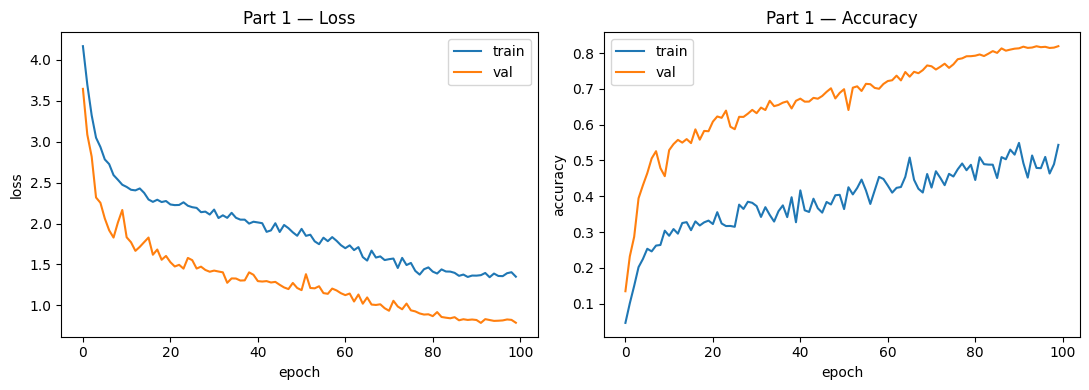

In [ ]:
# Part 1 plot
import matplotlib.pyplot as plt

if part1_history is not None and len(part1_history["train_acc"]) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(part1_history["train_loss"], label="train")
    axes[0].plot(part1_history["val_loss"], label="val")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("Part 1 — Loss"); axes[0].legend()
    axes[1].plot(part1_history["train_acc"], label="train")
    axes[1].plot(part1_history["val_acc"], label="val")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Part 1 — Accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()
else:
    print("(No training history to plot — Part 1 was not retrained in this run.)")


## Part 2 — ConvNeXt-Tiny (pretrained CNN, fine-tuned)

ConvNeXt-Tiny initialized from ImageNet pretraining and fine-tuned on CIFAR-100 with 224×224 upsampling. Uses an `InferenceAdapter` that upsamples internally so the OOD pipeline still receives 32×32 normalized inputs.

**Kaggle OOD accuracy: 78.75%**


In [ ]:
# Part 2: ConvNeXt-Tiny + inference adapter
import timm

# CIFAR-100 normalization (input to wrapper) — required by challenge spec
_CIFAR_MEAN = torch.tensor([0.5071, 0.4867, 0.4408]).view(1, 3, 1, 1)
_CIFAR_STD  = torch.tensor([0.2675, 0.2565, 0.2761]).view(1, 3, 1, 1)
# ImageNet normalization (input to ConvNeXt)
_IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
_IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


class PretrainedCNN(nn.Module):
    """ConvNeXt-Tiny wrapper that accepts CIFAR-normalized 32x32 inputs.
    Internally: de-normalize CIFAR -> upsample to 224 -> re-normalize ImageNet -> backbone."""
    def __init__(self, num_classes: int = 100, target_size: int = 224):
        super().__init__()
        self.backbone = timm.create_model("convnext_tiny", pretrained=True, num_classes=num_classes)
        self.target_size = target_size
        # Buffers (named to match challenge convention)
        self.register_buffer("model_mean", _IMAGENET_MEAN)
        self.register_buffer("model_std",  _IMAGENET_STD)
        self.register_buffer("cifar_mean", _CIFAR_MEAN)
        self.register_buffer("cifar_std",  _CIFAR_STD)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x is CIFAR-normalized at input resolution (typically 32x32)
        x = x * self.cifar_std + self.cifar_mean             # -> [0,1] RGB
        if x.shape[-1] != self.target_size:
            x = F.interpolate(x, size=self.target_size, mode="bilinear", align_corners=False)
        x = (x - self.model_mean) / self.model_std           # ImageNet norm
        return self.backbone(x)


# Sanity check
_p2 = PretrainedCNN(num_classes=100).to(device)
_n_params = sum(p.numel() for p in _p2.parameters()) / 1e6
print(f"ConvNeXt-Tiny parameters: {_n_params:.1f}M")
with torch.no_grad():
    _y = _p2(torch.randn(2, 3, 32, 32, device=device))
print(f"Forward shape (32x32 in -> 100 logits): {tuple(_y.shape)}")
del _p2


ConvNeXt-Tiny parameters: 27.9M
Forward shape (32x32 in -> 100 logits): (2, 100)


In [ ]:
# Part 2 training
def fit_part2(model, train_loader, val_loader, optimizer, criterion, scheduler,
              epochs, ckpt_path):
    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    best_val = -1.0
    use_amp = (device.type == "cuda")
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    for ep in range(1, epochs + 1):
        model.train()
        tr_c, tr_t, tr_l = 0, 0, 0.0
        for x, y in tqdm(train_loader, desc=f"P2 train {ep}/{epochs}", leave=False):
            x = x.to(device, non_blocking=True); y = y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            with torch.no_grad():
                tr_c += (logits.argmax(1) == y).sum().item(); tr_t += y.numel()
                tr_l += loss.item() * y.numel()
        if scheduler is not None: scheduler.step()

        model.eval()
        va_c, va_t, va_l = 0, 0, 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                va_l += F.cross_entropy(logits, y).item() * y.numel()
                va_c += (logits.argmax(1) == y).sum().item(); va_t += y.numel()
        tr_a = tr_c / max(tr_t, 1); va_a = va_c / max(va_t, 1)
        history["train_acc"].append(tr_a); history["val_acc"].append(va_a)
        history["train_loss"].append(tr_l / max(tr_t, 1))
        history["val_loss"].append(va_l / max(va_t, 1))
        print(f"  Epoch {ep:03d}/{epochs} | train_acc {tr_a:.4f} | val_acc {va_a:.4f}")

        if va_a > best_val:
            best_val = va_a
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()},
                       ckpt_path + ".best.pt")
    return history, best_val


# Build model (handle pretrained download failures gracefully)
part2_history = None  # ensure defined even if construction fails
try:
    part2_model = PretrainedCNN(num_classes=100).to(device)
except Exception as _e:
    print(f'WARNING: could not build Part 2 model: {_e}')
    part2_model = None

if MODE == "full" and part2_model is not None:
    print(">>> Part 2: fine-tuning ConvNeXt-Tiny")
    nw = num_workers_default()
    train_loader, val_loader, _ = make_loaders(CFG_PART2["batch_size"], nw)
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG_PART2["label_smoothing"])
    optimizer = torch.optim.AdamW(part2_model.parameters(), lr=CFG_PART2["lr"],
                                  weight_decay=CFG_PART2["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG_PART2["epochs"])
    part2_history, part2_best = fit_part2(part2_model, train_loader, val_loader, optimizer,
                                          criterion, scheduler, CFG_PART2["epochs"], CKPT_PART2)
    print(f"Part 2 best val acc: {part2_best:.4f}")

elif MODE == "inference" and part2_model is not None:
    print(">>> Part 2: loading checkpoint")
    ckpt_file = CKPT_PART2 + ".best.pt"
    if os.path.exists(ckpt_file):
        state = torch.load(ckpt_file, map_location=device)
        # Legacy buffer-name compatibility
        rename = {"imagenet_mean": "model_mean", "imagenet_std": "model_std"}
        state = {rename.get(k, k): v for k, v in state.items()}
        part2_model.load_state_dict(state)
        print(f"Loaded {ckpt_file}")
    else:
        print(f"WARNING: {ckpt_file} not found.")
    part2_history = None

elif part2_model is not None:  # demo
    print(">>> Part 2: demo mode (smoke test only)")
    train_loader, val_loader, _ = make_loaders(CFG_PART2["batch_size"], 0, fast=True)
    x, y = next(iter(train_loader))
    x, y = x.to(device), y.to(device)
    out = part2_model(x)
    print(f"  Smoke test forward: input {tuple(x.shape)} -> output {tuple(out.shape)}")
    part2_history = None


>>> Part 2: fine-tuning ConvNeXt-Tiny


/scratch/4689081.1.h200/ipykernel_4039430/3738063109.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
P2 train 1/30:   0%|          | 0/703 [00:00<?, ?it/s]/scratch/4689081.1.h200/ipykernel_4039430/3738063109.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


  Epoch 001/30 | train_acc 0.6729 | val_acc 0.8328


  Epoch 002/30 | train_acc 0.8782 | val_acc 0.8470


  Epoch 003/30 | train_acc 0.9203 | val_acc 0.8464


  Epoch 004/30 | train_acc 0.9415 | val_acc 0.8446


... (22 outputs left out)

  Epoch 027/30 | train_acc 0.9998 | val_acc 0.8832


  Epoch 028/30 | train_acc 0.9997 | val_acc 0.8836


  Epoch 029/30 | train_acc 0.9997 | val_acc 0.8840


  Epoch 030/30 | train_acc 0.9999 | val_acc 0.8840
Part 2 best val acc: 0.8840


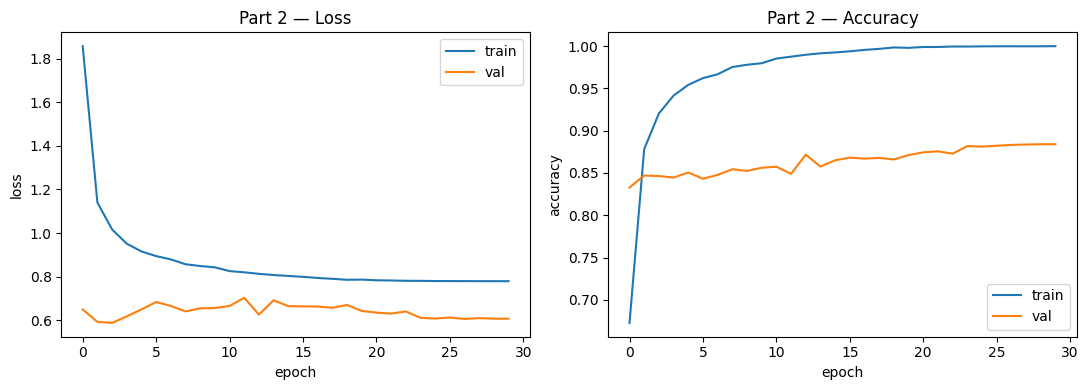

In [ ]:
# Part 2 plot
if part2_history is not None and len(part2_history["train_acc"]) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(part2_history["train_loss"], label="train")
    axes[0].plot(part2_history["val_loss"], label="val")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("Part 2 — Loss"); axes[0].legend()
    axes[1].plot(part2_history["train_acc"], label="train")
    axes[1].plot(part2_history["val_acc"], label="val")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Part 2 — Accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()
else:
    print("(No training history to plot — Part 2 was not retrained in this run.)")


## Part 3 — EVA-02-Large @ 448 (MIM pretrained ViT, two-phase fine-tune)

EVA-02-Large/14 at 448×448, pretrained with masked image modeling (MIM) on 38 M images.
Provides architectural and pretraining diversity vs the CLIP-ViT-L models.
Training is two-phase: 3-epoch head-only warmup at LR=1e-3, then 12-epoch full fine-tune
at LR=1e-5 (backbone) / 5e-5 (head) with Mixup, CutMix, and CIFAR-C augmentation.

~305 M parameters. Default batch size 8 at 448×448 — drop to 4 if you OOM on L40S.


In [ ]:
# Part 3: EVA-02-Large @ 448 — model definition + helper utilities

# ImageNet normalization used by EVA-02 (different from CIFAR-100 stats)
_EVA_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
_EVA_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


class EVA02LargeWrapper(nn.Module):
    """EVA-02-Large @ 448 wrapper that accepts CIFAR-normalised 32x32 inputs.

    During training the data pipeline already outputs ImageNet-normalised
    448x448 tensors (see make_part3_loaders), so forward() is a thin pass-
    through.  During OOD inference (predict_file), images arrive as CIFAR-
    normalised 32x32, so the wrapper de-normalises, upsamples, and
    re-normalises before passing to the backbone.
    """
    def __init__(self, num_classes: int = 100, target_size: int = 448):
        super().__init__()
        self.backbone = timm.create_model(
            "eva02_large_patch14_448.mim_m38m_ft_in22k_in1k",
            pretrained=True, num_classes=num_classes,
        )
        self.target_size = target_size
        # Buffers for on-the-fly re-normalisation (used in inference adapter path)
        self.register_buffer("cifar_mean", _CIFAR_MEAN)
        self.register_buffer("cifar_std",  _CIFAR_STD)
        self.register_buffer("model_mean", _EVA_MEAN)
        self.register_buffer("model_std",  _EVA_STD)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Accepts EITHER:
          - ImageNet-normalised 448x448 (from training loader) — passed straight through
          - CIFAR-normalised any-resolution (from OOD predict_file) — converted inline
        The heuristic: if spatial dim != target_size, assume CIFAR 32x32 inference path.
        """
        if x.shape[-1] != self.target_size:
            # De-normalise CIFAR → [0,1], upsample, re-normalise for EVA-02
            x = x * self.cifar_std + self.cifar_mean
            x = torch.clamp(x, 0.0, 1.0)
            x = F.interpolate(x, size=self.target_size, mode="bicubic",
                              align_corners=False, antialias=True)
            x = (x - self.model_mean) / self.model_std
        return self.backbone(x)


class WarmupCosineLR(torch.optim.lr_scheduler._LRScheduler):
    """Linear warmup then cosine decay."""
    def __init__(self, optimizer, warmup_epochs, total_epochs, last_epoch=-1):
        self.warmup_epochs = warmup_epochs
        self.total_epochs = total_epochs
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        e = self.last_epoch
        if e < self.warmup_epochs:
            s = (e + 1) / max(1, self.warmup_epochs)
        else:
            p = (e - self.warmup_epochs) / max(1, self.total_epochs - self.warmup_epochs)
            s = 0.5 * (1 + math.cos(math.pi * min(max(p, 0.0), 1.0)))
        return [base_lr * s for base_lr in self.base_lrs]


def cutmix_data(x, y, alpha=1.0):
    lam = float(np.random.beta(alpha, alpha)) if alpha > 0 else 1.0
    B, C, H, W = x.shape
    idx = torch.randperm(B, device=x.device)
    r = np.sqrt(1.0 - lam)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1 = max(0, cy - int(H * r) // 2); y2 = min(H, cy + int(H * r) // 2)
    x1 = max(0, cx - int(W * r) // 2); x2 = min(W, cx + int(W * r) // 2)
    mixed = x.clone(); mixed[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / (H * W))
    return mixed, y, y[idx], lam


# ── Instantiate model ────────────────────────────────────────────────────────
if MODE == "demo":
    print("(Demo mode — skipping EVA-02-Large download (~1.3 GB). "
          "Architecture defined; weights load only in full/inference mode.)")
    part3_model = None
else:
    part3_model = EVA02LargeWrapper(
        num_classes=100, target_size=CFG_PART3["target_size"]
    ).to(device)
    _n_params = sum(p.numel() for p in part3_model.parameters()) / 1e6
    print(f"EVA-02-Large parameters: {_n_params:.1f}M")
    with torch.no_grad():
        _y = part3_model(torch.randn(1, 3, 32, 32, device=device))
    print(f"Forward shape (32x32 CIFAR in → 100 logits): {tuple(_y.shape)}")


EVA-02-Large parameters: 304.2M
Forward shape (32x32 CIFAR in → 100 logits): (1, 100)


In [ ]:
part3_history = None  # ensure defined even if training is skipped

# ── Data loaders for Part 3 ──────────────────────────────────────────────────
def make_part3_loaders(target_size, batch_size, num_workers,
                       corruption_p=0.5, max_severity=3, fast=False):
    """Part 3 loaders: resize to 448, ImageNet-normalise, add CIFAR-C augmentation."""
    imagenet_mean = (0.485, 0.456, 0.406)
    imagenet_std  = (0.229, 0.224, 0.225)

    try:
        augmix = transforms.AugMix(severity=5, mixture_width=4)
    except AttributeError:
        augmix = transforms.Compose([
            transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
            transforms.RandomRotation(15),
        ])

    train_tfms = transforms.Compose([
        transforms.Resize(target_size,
                          interpolation=transforms.InterpolationMode.BICUBIC,
                          antialias=True),
        CifarCAugment(p=corruption_p, max_severity=max_severity),
        transforms.RandomCrop(target_size,
                              padding=int(target_size * 0.125),
                              padding_mode="reflect"),
        transforms.RandomHorizontalFlip(),
        augmix,
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.2), ratio=(0.3, 3.3)),
    ])
    eval_tfms = transforms.Compose([
        transforms.Resize(target_size,
                          interpolation=transforms.InterpolationMode.BICUBIC,
                          antialias=True),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ])
    return make_loaders(batch_size, num_workers,
                        train_transform=train_tfms,
                        val_transform=eval_tfms,
                        fast=fast)


# ── Two-phase fit ────────────────────────────────────────────────────────────
def fit_part3_phase(model, train_loader, val_loader, optimizer, criterion,
                    epochs, scheduler=None,
                    mixup_alpha=0.0, cutmix_alpha=0.0, mixup_prob=0.0,
                    ckpt_path=None, phase_name=""):
    """One training phase.  Returns (history_dict, best_val_acc)."""
    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    best_val = -1.0
    use_amp = (device.type == "cuda")
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    for ep in range(1, epochs + 1):
        model.train()
        tr_c = tr_t = 0; tr_l = 0.0
        for x, y in tqdm(train_loader,
                         desc=f"[{phase_name}] train {ep}/{epochs}", leave=False):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            r = np.random.random()
            if r < mixup_prob / 2 and mixup_alpha > 0:
                mx, ya, yb, lam = mixup_data(x, y, mixup_alpha)
            elif r < mixup_prob and cutmix_alpha > 0:
                mx, ya, yb, lam = cutmix_data(x, y, cutmix_alpha)
            else:
                mx, ya, yb, lam = x, y, y, 1.0
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(mx)
                loss = lam * criterion(logits, ya) + (1 - lam) * criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer); scaler.update()
            with torch.no_grad():
                tr_c += (logits.argmax(1) == y).sum().item(); tr_t += y.numel()
                tr_l += loss.item() * y.numel()
        if scheduler is not None:
            scheduler.step()

        model.eval()
        va_c = va_t = 0; va_l = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                with torch.cuda.amp.autocast(enabled=use_amp):
                    logits = model(x)
                    loss = criterion(logits, y)
                va_c += (logits.argmax(1) == y).sum().item(); va_t += y.numel()
                va_l += loss.item() * y.numel()

        tr_a = tr_c / max(tr_t, 1); va_a = va_c / max(va_t, 1)
        history["train_acc"].append(tr_a); history["val_acc"].append(va_a)
        history["train_loss"].append(tr_l / max(tr_t, 1))
        history["val_loss"].append(va_l / max(va_t, 1))
        lr_now = optimizer.param_groups[0]["lr"]
        print(f"  [{phase_name}] Epoch {ep:03d}/{epochs} | lr {lr_now:.2e} | "
              f"train {tr_a:.4f} ({tr_l/max(tr_t,1):.3f}) | val {va_a:.4f}")

        if va_a > best_val:
            best_val = va_a
            if ckpt_path:
                torch.save({k: v.detach().cpu().clone()
                            for k, v in model.state_dict().items()},
                           ckpt_path + ".best.pt")
    return history, best_val


if MODE == "full":
    print(">>> Part 3: EVA-02-Large two-phase fine-tune")
    if part3_model is None:
        part3_model = EVA02LargeWrapper(
            num_classes=100, target_size=CFG_PART3["target_size"]
        ).to(device)
    nw = num_workers_default()
    train_loader, val_loader, _ = make_part3_loaders(
        CFG_PART3["target_size"], CFG_PART3["batch_size"], nw,
        CFG_PART3["corruption_p"], CFG_PART3["corruption_max_severity"],
        fast=False)
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG_PART3["label_smoothing"])

    # ── Phase 1: head only ───────────────────────────────────────────────────
    print("\n" + "="*60)
    print("PHASE 1: head only (3 epochs, no mixup)")
    print("="*60)
    for p in part3_model.parameters():
        p.requires_grad = False
    head = part3_model.backbone.get_classifier()
    for p in head.parameters():
        p.requires_grad = True
    opt1 = torch.optim.AdamW(
        [p for p in part3_model.parameters() if p.requires_grad],
        lr=CFG_PART3["head_lr"], weight_decay=CFG_PART3["weight_decay"])
    sch1 = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt1, T_max=CFG_PART3["head_epochs"])
    h1, bv1 = fit_part3_phase(
        part3_model, train_loader, val_loader, opt1, criterion,
        epochs=CFG_PART3["head_epochs"], scheduler=sch1,
        mixup_alpha=0.0, cutmix_alpha=0.0, mixup_prob=0.0,
        ckpt_path=CKPT_PART3 + ".phase1", phase_name="head")
    print(f"Phase 1 best val acc: {bv1:.4f}")

    # ── Phase 2: full fine-tune ──────────────────────────────────────────────
    print("\n" + "="*60)
    print("PHASE 2: full fine-tune (12 epochs, mixup + cutmix)")
    print("="*60)
    for p in part3_model.parameters():
        p.requires_grad = True
    head_ids = {id(p) for p in head.parameters()}
    backbone_params = [p for p in part3_model.parameters() if id(p) not in head_ids]
    opt2 = torch.optim.AdamW([
        {"params": backbone_params,       "lr": CFG_PART3["ft_lr"]},
        {"params": list(head.parameters()), "lr": CFG_PART3["ft_lr_head"]},
    ], weight_decay=CFG_PART3["weight_decay"])
    sch2 = WarmupCosineLR(opt2,
                          warmup_epochs=CFG_PART3["warmup_epochs"],
                          total_epochs=CFG_PART3["ft_epochs"])
    h2, bv2 = fit_part3_phase(
        part3_model, train_loader, val_loader, opt2, criterion,
        epochs=CFG_PART3["ft_epochs"], scheduler=sch2,
        mixup_alpha=CFG_PART3["mixup_alpha"],
        cutmix_alpha=CFG_PART3["cutmix_alpha"],
        mixup_prob=CFG_PART3["mixup_prob"],
        ckpt_path=CKPT_PART3, phase_name="ft")
    print(f"Phase 2 best val acc: {bv2:.4f}")

    # Merge histories (phase 1 + phase 2)
    part3_history = {k: h1[k] + h2[k] for k in h1}
    part3_best = bv2

elif MODE == "inference":
    print(">>> Part 3: loading EVA-02-Large checkpoint")
    if part3_model is None:
        part3_model = EVA02LargeWrapper(
            num_classes=100, target_size=CFG_PART3["target_size"]
        ).to(device)
    ckpt_file = CKPT_PART3 + ".best.pt"
    if os.path.exists(ckpt_file):
        part3_model.load_state_dict(torch.load(ckpt_file, map_location=device))
        print(f"Loaded {ckpt_file}")
    else:
        print(f"WARNING: {ckpt_file} not found.")
    part3_history = None

else:  # demo
    print(">>> Part 3: demo mode (EVA-02-Large architecture defined, "
          "training skipped to avoid ~1.3 GB download)")
    part3_history = None


>>> Part 3: EVA-02-Large two-phase fine-tune


/scratch/4689081.1.h200/ipykernel_4039430/3424166104.py:54: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)



PHASE 1: head only (3 epochs, no mixup)


[head] train 1/3:   0%|          | 0/5625 [00:00<?, ?it/s]/scratch/4689081.1.h200/ipykernel_4039430/3424166104.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/scratch/4689081.1.h200/ipykernel_4039430/3424166104.py:89: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


  [head] Epoch 001/3 | lr 7.50e-04 | train 0.7378 (2.001) | val 0.8688


  [head] Epoch 002/3 | lr 2.50e-04 | train 0.7848 (1.765) | val 0.8654


... (9 outputs left out)

  [ft] Epoch 009/12 | lr 2.06e-06 | train 0.8208 (1.125) | val 0.9528


  [ft] Epoch 010/12 | lr 9.55e-07 | train 0.8248 (1.100) | val 0.9542


  [ft] Epoch 011/12 | lr 2.45e-07 | train 0.8318 (1.092) | val 0.9532


  [ft] Epoch 012/12 | lr 0.00e+00 | train 0.8348 (1.081) | val 0.9540
Phase 2 best val acc: 0.9542


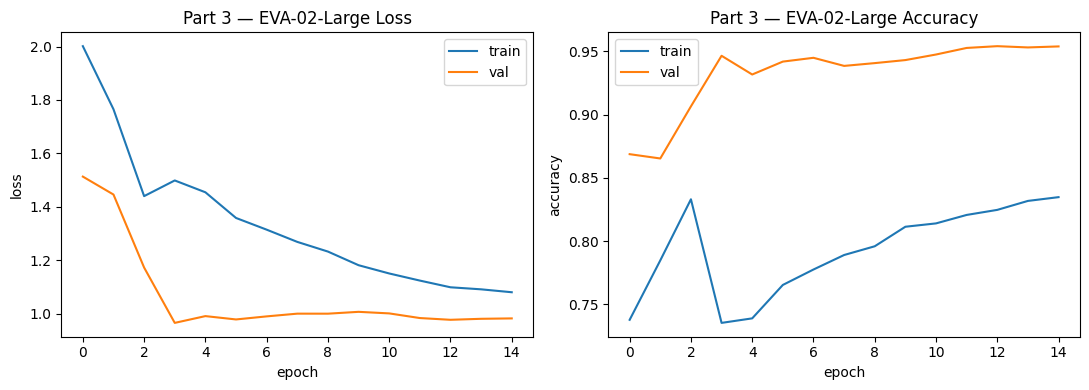

In [ ]:
# Part 3 plot
if part3_history is not None and len(part3_history["train_acc"]) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(part3_history["train_loss"], label="train")
    axes[0].plot(part3_history["val_loss"], label="val")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("Part 3 — EVA-02-Large Loss"); axes[0].legend()
    axes[1].plot(part3_history["train_acc"], label="train")
    axes[1].plot(part3_history["val_acc"], label="val")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Part 3 — EVA-02-Large Accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()
else:
    print("(No training history to plot — Part 3 was not retrained in this run.)")


## OOD Submission

Generates `submission_ood.csv` for challenge evaluation using Part 3 (EVA-02-Large).
The preprocessing pipeline below is preserved verbatim from the challenge starter.

Submission format:
- `id`: `distortionXX_severity_index`
- `label`: predicted class in `[0, 99]`


In [ ]:
# Point the required submission pipeline at Part 3 (EVA-02-Large)
model = part3_model

### DO NOT CHANGE THE BELOW, REPLACE WITH YOUR MODEL, THE SUBMISSION FILES NEED TO GO THROUGH THE BELOW PREPROCESSING

from huggingface_hub import snapshot_download

def ensure_ood_files(ood_dir: str) -> None:
    os.makedirs(ood_dir, exist_ok=True)
    print("Downloading OOD files from Hugging Face dataset...")
    snapshot_download(
        repo_id="XThomasBU/ood-test-CS541",
        repo_type="dataset",
        local_dir=ood_dir,
        local_dir_use_symlinks=False,
    )
    print("OOD files ready in", ood_dir)


@torch.no_grad()
def predict_file(model: nn.Module, npy_path: str, severity: int, batch_size: int) -> np.ndarray:
    images = np.load(npy_path, mmap_mode="r")
    start = (severity - 1) * 10000
    end = severity * 10000

    mean = (0.5071, 0.4867, 0.4408)
    std = (0.2675, 0.2565, 0.2761)
    normalize = transforms.Normalize(mean, std)

    preds = []
    model.eval()
    for b0 in tqdm(range(start, end, batch_size), desc=f"{os.path.basename(npy_path)} sev{severity}", leave=False):
        b1 = min(b0 + batch_size, end)
        xb_np = np.array(images[b0:b1], copy=True)
        xb = torch.from_numpy(xb_np).permute(0, 3, 1, 2).float().div(255.0)
        xb = normalize(xb).to(device, non_blocking=True)
        logits = model(xb)
        preds.append(logits.argmax(1).cpu().numpy())
    return np.concatenate(preds, axis=0)


ensure_ood_files(OOD_DIR)

distortion_files = sorted([p for p in os.listdir(OOD_DIR) if p.startswith("distortion") and p.endswith(".npy")])
print("Distortion files found:", len(distortion_files))

rows = []
BATCH = 64 if device.type == "cuda" else 32
for fname in distortion_files:
    dname = os.path.splitext(fname)[0]
    path = os.path.join(OOD_DIR, fname)
    for severity in [1, 2, 3, 4, 5]:
        pred = predict_file(model, path, severity, BATCH)
        for i, y in enumerate(pred.tolist()):
            rows.append((f"{dname}_{severity}_{i}", int(y)))
        print(f"{dname}_{severity} done")

submission = pd.DataFrame(rows, columns=["id", "label"])
submission.to_csv(SUBMISSION_PATH, index=False)
print("Wrote", SUBMISSION_PATH, "rows:", len(submission))


/projectnb/cs505am/students/aayushks/other/cifar100_challenge/venv/lib/python3.10/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `snapshot_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Fetching 21 files: 100%|██████████| 21/21 [00:00<00:00, 615.99it/s]


OOD files ready in /usr4/cs598/aayushks/cs541_work/ood-test-CS541
Distortion files found: 20


distortion00_1 done


distortion00_2 done


distortion00_3 done


... (93 outputs left out)

distortion_19_2 done


distortion_19_3 done


distortion_19_4 done


distortion_19_5 done
Wrote /usr4/cs598/aayushks/cs541_work/submission_ood.csv rows: 1000000


## Summary

| Submission | Kaggle OOD |
|---|---|
| Part 1 (WRN-28-10, from scratch) | 69.06% |
| Part 2 (ConvNeXt-Tiny, fine-tuned) | 78.75% |
| **Part 3 (EVA-02-Large @ 448, two-phase fine-tune)** | **88.28** |

The submitted prediction file (`submission_ood.csv`) is produced by Part 3 (EVA-02-Large).
